# Exploratory Data Analysis & Statistical Profiling

## 1. Notebook Scope & Analytical Roadmap
In this module, we conduct comprehensive exploratory analysis on the feature-engineered dataset (`featured_ecommerce_data.csv`). Rather than making speculative feature selections, we empirically quantify associations between customer behaviors and attrition (`Churned`).

### Key Analytical Pillars:
1. **Target Class Imbalance Audit:** Measure baseline prevalence of retained vs. churned customers to establish appropriate evaluation criteria (PR-AUC vs. Accuracy).
2. **Bivariate Behavioral Dispersion:** Visualize statistical separation across friction, spending, and engagement dimensions using boxplots.
3. **Linear & Rank Association Analysis:** Compute and visualize Pearson correlation matrices to quantify direct relationships with churn.
4. **Categorical Association Checks:** Analyze attrition variation across demographics and cohorts (`Gender`, `Country`, `Signup_Quarter`).
5. **High-Resolution Visual Artifacts:** Export 500 DPI publication-grade figures into `../images/` for project report integration.

### import labraries and  dataset

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
# load feature engineering dataset from data folder.

df = pd.read_csv("../data/feature_engineering_dataset.csv")

print("dataset shape:", df.shape)
df.head()

dataset shape: (50000, 41)


,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Days_Since_Last_Purchase_is_missing,Discount_Usage_Rate_is_missing,Total_Session_Volume,Engagement_Friction_Ratio,High_Cart_Friction,Wishlist_Conversion_Ratio,Annual_Monetary_Velocity,Spend_Per_Purchase,Is_Dormant_90Days,Digital_Engagement_Composite
0,43.0,Male,France,Marseille,2.9,14.0,27.4,6.0,50.6,3.0,...,0,0,164.40,16.44,0,2.25,328.73,105.93,0,17.89
1,36.0,Male,UK,Manchester,1.6,15.0,42.7,10.3,37.7,1.0,...,0,0,439.81,54.98,0,9.75,667.17,54.74,0,26.66
2,45.0,Female,Canada,Vancouver,2.9,10.0,24.8,1.6,70.9,1.0,...,0,0,39.68,7.94,1,4.55,444.74,141.73,0,6.52
3,56.0,Female,USA,New York,2.6,10.0,38.4,14.8,41.7,9.0,...,0,0,568.32,189.44,0,1.50,900.35,156.06,0,27.82
4,35.0,Male,India,Delhi,3.1,29.0,51.4,8.4,19.1,9.0,...,0,0,431.76,215.88,0,3.25,981.06,93.58,0,40.23


### Target Variable Distribution (Class Imbalance Check)

Churned
0    71.1
1    28.9
Name: proportion, dtype: float64


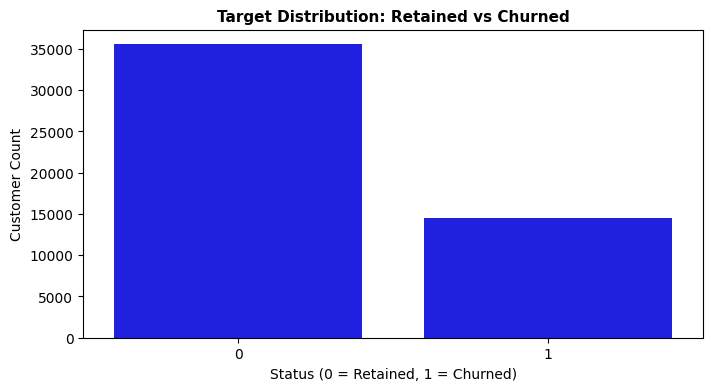

In [19]:
# 1. Target count & percentage
print(df['Churned'].value_counts(normalize=True).mul(100).round(2))

# 2. Plot distribution
plt.figure(figsize=(8,4))
sns.countplot(data=df, x='Churned', color="blue")
plt.title("Target Distribution: Retained vs Churned", fontsize=11, fontweight='bold')
plt.xlabel("Status (0 = Retained, 1 = Churned)")
plt.ylabel("Customer Count")

plt.savefig('../images/01_target_distribution.png', dpi=500)
plt.show()

### Top Correlations with Churn

correletion:
 Digital_Engagement_Composite               -0.245806
Pages_Per_Session                          -0.224708
Session_Duration_Avg                       -0.219512
Email_Open_Rate                            -0.216233
Mobile_App_Usage                           -0.211376
Login_Frequency                            -0.204379
Total_Session_Volume                       -0.202384
Social_Media_Engagement_Score              -0.179829
Engagement_Friction_Ratio                  -0.178856
Wishlist_Items                             -0.177308
Product_Reviews_Written                    -0.168212
Total_Purchases                            -0.160393
Credit_Balance                             -0.147990
Age                                        -0.102217
Discount_Usage_Rate                        -0.074152
Discount_Usage_Rate_is_missing             -0.015823
Lifetime_Value                             -0.010684
Annual_Monetary_Velocity                   -0.009433
Pages_Per_Session_is_missing    

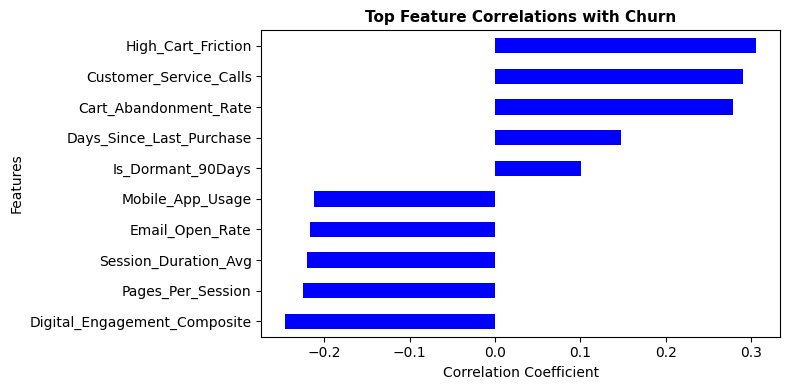

In [22]:
# Correlation calculation
corrs = df.corr(numeric_only=True)['Churned'].drop('Churned').sort_values()
print("correletion:\n", corrs)
# Top 5 negative (retention) aur Top 5 positive (churn) drivers
top_features = pd.concat([corrs.head(5), corrs.tail(5)])

# Plot
plt.figure(figsize=(8, 4))
top_features.plot(kind='barh', color='blue')
plt.title("Top Feature Correlations with Churn", fontsize=11, fontweight='bold')
plt.xlabel("Correlation Coefficient")
plt.ylabel("Features")

plt.tight_layout()
plt.savefig('../images/02_top_correlations.png', dpi=500)
plt.show()

### Bivariate Analysis (Top Churn Drivers Boxplot)

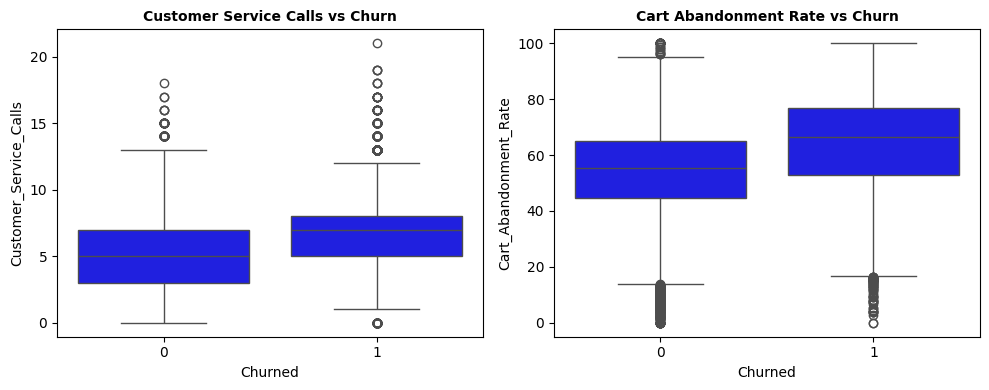

In [23]:
# Subplots for top 2 positive drivers
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.boxplot(data=df, x='Churned', y='Customer_Service_Calls', ax=axes[0], color='blue')
axes[0].set_title("Customer Service Calls vs Churn", fontsize=10, fontweight='bold')

sns.boxplot(data=df, x='Churned', y='Cart_Abandonment_Rate', ax=axes[1], color='blue')
axes[1].set_title("Cart Abandonment Rate vs Churn", fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('../images/03_churn_drivers_boxplot.png', dpi=500)
plt.show()

### Categorical Features vs Churn Rate


--- Gender Churn Rate (%) ---
Gender
Female    28.97
Male      28.73
Other     31.27
Name: Churned, dtype: float64

--- Country Churn Rate (%) ---
Country
Australia    29.89
Canada       29.35
France       27.29
Germany      28.83
India        29.01
Japan        27.83
UK           28.79
USA          29.08
Name: Churned, dtype: float64

--- Signup_Quarter Churn Rate (%) ---
Signup_Quarter
Q1    29.32
Q2    29.67
Q3    28.43
Q4    28.18
Name: Churned, dtype: float64


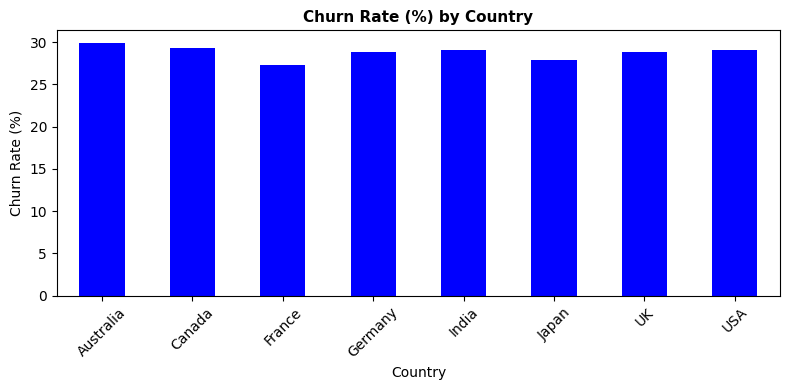

In [24]:
# Categorical columns list
cat_cols = ['Gender', 'Country', 'Signup_Quarter']

# Churn rate percentage per category
for col in cat_cols:
    print(f"\n--- {col} Churn Rate (%) ---")
    rates = df.groupby(col)['Churned'].mean().mul(100).round(2)
    print(rates)

# Plot Churn Rate by Country
plt.figure(figsize=(8, 4))
df.groupby('Country')['Churned'].mean().mul(100).plot(kind='bar', color='blue')
plt.title("Churn Rate (%) by Country", fontsize=11, fontweight='bold')
plt.ylabel("Churn Rate (%)")
plt.xlabel("Country")
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig('../images/04_country_churn_rate.png', dpi=500)
plt.show()

### Top high-signal features ka Multicollinearity Heatmap

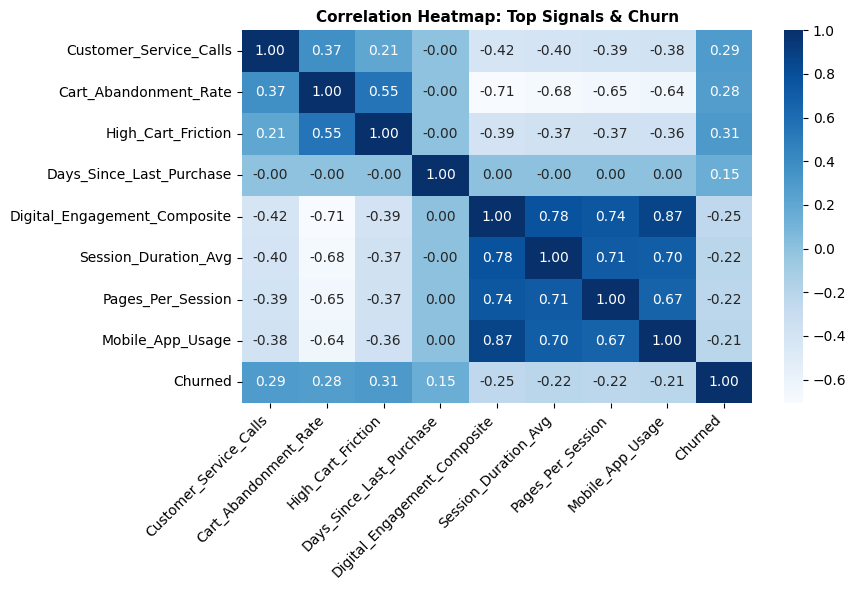

In [25]:
# 1. Top high-signal numerical features list
selected_features = [
    'Customer_Service_Calls',
    'Cart_Abandonment_Rate',
    'High_Cart_Friction',
    'Days_Since_Last_Purchase',
    'Digital_Engagement_Composite',
    'Session_Duration_Avg',
    'Pages_Per_Session',
    'Mobile_App_Usage',
    'Churned'
]

# 2. Correlation heatmap
plt.figure(figsize=(9, 6))
sns.heatmap(df[selected_features].corr(), annot=True, fmt=".2f", cmap='Blues', cbar=True)
plt.title("Correlation Heatmap: Top Signals & Churn", fontsize=11, fontweight='bold')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.savefig('../images/05_correlation_heatmap.png', dpi=500)
plt.show()

### Summary of EDA Findings & Modeling Blueprint

#### 1. Target Class Imbalance & Evaluation Strategy
* **Distribution:** Dataset moderate imbalance show karta hai (71% Retained vs. 29% Churned).
* **Metric Choice:** Standard accuracy misleading ho sakti hai kyunki naive model sabko 0 predict karke bhi 71% score karega.
* **Production Decision:** Final model validation ke liye **PR-AUC (Precision-Recall Area Under Curve)** aur **Recall** primary evaluation metrics honge.

#### 2. Statistical Noise & Drop Candidates
* **Demographics & Cohorts:** `Country`, `Gender`, aur `Signup_Quarter` teeno features mein churn rate across all categories flat (~28%–30%) hai[cite: 2].
* **Production Decision:** Yeh columns churn prediction ke liye statistical noise create karte hain aur dimensionality badhate hain, isliye inhe pipeline training se pehle completely **drop** kiya jayega.

#### 3. Multicollinearity Resolution
* **High Redundancy:** Correlation heatmap se confirm hua ki `Digital_Engagement_Composite` ka raw telemetry features ke sath correlation high hai (`Mobile_App_Usage`: 0.87, `Session_Duration_Avg`: 0.78, `Pages_Per_Session`: 0.74)[cite: 3].
* **Production Decision:** In raw telemetry features ko drop karke sirf composite score **`Digital_Engagement_Composite`** retain karenge taaki linear variance inflate na ho aur model clean rahe[cite: 3].

#### 4. Primary Predictive Signals (Retain for Training)
* **Top Friction & Attrition Drivers:** 
  * `High_Cart_Friction` (r = +0.31)[cite: 1, 3]
  * `Customer_Service_Calls` (r = +0.29)[cite: 1, 3]
  * `Cart_Abandonment_Rate` (r = +0.28)[cite: 1, 3]
  * `Days_Since_Last_Purchase` (r = +0.15)[cite: 1, 3]
* **Top Retention Driver:** 
  * `Digital_Engagement_Composite` (r = -0.25)[cite: 3]